# Models, Evaluation and Results
**MSP470S project, notebook 3 of 4**

| | |
|---|---|
| **Project title** | Talent Matching: A Graph Neural Network Recommender for Ranking Candidate–Employer Matches |
| **Author** | Luyolo Sokatsha (student number 217148875) |
| **Module** | MSP470S Mathematical Sciences Project 4 |
| **Qualification** | Advanced Diploma in Mathematical Sciences |
| **Institution** | Cape Peninsula University of Technology (CPUT) |
| **Date** | November 2026 |

## Project in one paragraph
Talent-matching platforms must decide which employers to show each candidate first. This project compares a graph neural network (GNN) with simpler recommenders (popularity, BPR matrix factorisation, logistic regression) on **fully synthetic** candidate–employer data, using a time-based test, Recall@K and NDCG@K, an ablation, a cold-start test and a sensitivity analysis. No real people, companies or confidential records are used.

## What this notebook does
Trains and evaluates the popularity baseline, Solution A (BPR matrix factorisation), Solution B and B+ (logistic regression without and with employer popularity) and Solution C (heterogeneous GraphSAGE GNN) plus two ablations. Settings are chosen on the validation period only; every learned model is then trained with five seeds and tested once on the final four months. It also runs a paired bootstrap, permutation importance, a worked example, a function that ranks employers for a new candidate, and saves the trained model and a model card.

| | |
|---|---|
| **Needs** | Notebook 02 output (`data/*_clean.csv`). |
| **Produces** | Tables, figures, trained GNN weights and `model_card.json` in `results/` |
| **Run time** | About 8 minutes on a CPU (hyperparameter search included) |

## How to run
1. In Google Colab choose **Runtime → Run all** (or run the cells from top to bottom). A GPU is not required.
2. The setup cell can mount your Google Drive so that all files are kept between sessions in the folder `MyDrive/MSP470S_Project`. Set `USE_DRIVE = False` to work in temporary Colab storage instead.
3. Run the four notebooks in order: 01 → 02 → 03 → 04 (04 is optional and slow).

In [ ]:
import os, sys
USE_DRIVE = True
if "google.colab" in sys.modules and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    WORKDIR = "/content/drive/MyDrive/MSP470S_Project"
elif "google.colab" in sys.modules:
    WORKDIR = "/content/MSP470S_Project"
else:
    WORKDIR = os.environ.get("MSP_WORKDIR", os.path.abspath("MSP470S_Project"))
for sub in ("data", "results", "results_sensitivity"):
    os.makedirs(f"{WORKDIR}/{sub}", exist_ok=True)
print("Working folder:", WORKDIR)

Mounted at /content/drive
Working folder: /content/drive/MyDrive/MSP470S_Project


In [ ]:
import importlib.util, subprocess
if importlib.util.find_spec("torch_geometric") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "torch_geometric"])
os.environ["MSP_DATA"] = f"{WORKDIR}/data"        # cleaned files from Notebook 02
os.environ["MSP_OUT"] = f"{WORKDIR}/results"      # tables, figures, trained model, model card

In [ ]:
import os, json, time, warnings, itertools
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as Fn
from torch_geometric.nn import HeteroConv, SAGEConv
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings("ignore")
torch.set_num_threads(1)

DATA_DIR = os.environ.get("MSP_DATA", ".")
OUT_DIR = os.environ.get("MSP_OUT", "results"); os.makedirs(OUT_DIR, exist_ok=True)
SEEDS = [int(x) for x in os.environ.get("MSP_SEEDS", "0,1,2,3,4").split(",")]
FAST = os.environ.get("MSP_FAST") == "1"      # lighter search used by the sensitivity analysis
KS = [5, 10, 20]
TRAIN_END, VALID_END = "2026-03-01", "2026-07-01"    # months 1-16 | 17-20 | 21-24

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## 1. Load data, build the time-based and cold-start splits

In [ ]:
cand = pd.read_csv(f"{DATA_DIR}/candidates_clean.csv")
emp = pd.read_csv(f"{DATA_DIR}/employers_clean.csv")
inter = pd.read_csv(f"{DATA_DIR}/interactions_clean.csv", parse_dates=["event_date"])
nC, nE = len(cand), len(emp)
cmap = {c: k for k, c in enumerate(cand.candidate_id)}; emap = {e: k for k, e in enumerate(emp.employer_id)}
inter["u"] = inter.candidate_id.map(cmap); inter["i"] = inter.employer_id.map(emap)

rng0 = np.random.default_rng(470)                                    # same cold-start group as Step 1
cold_ids = set(rng0.choice(cand.candidate_id, int(0.10 * nC), replace=False))
is_cold = np.zeros(nC, bool); is_cold[[cmap[x] for x in cold_ids]] = True

train = inter[(inter.event_date < TRAIN_END) & ~is_cold[inter.u.values]]
valid = inter[(inter.event_date >= TRAIN_END) & (inter.event_date < VALID_END)]
test = inter[inter.event_date >= VALID_END]

def pair_matrix(df):
    M = np.zeros((nC, nE), bool); M[df.u.values, df.i.values] = True; return M

seen_train, seen_valid = pair_matrix(train), pair_matrix(valid)
w = ~is_cold[valid.u.values]; valid_T = pair_matrix(valid[w]) & ~seen_train
tw = ~is_cold[test.u.values]
test_T_warm = pair_matrix(test[tw]) & ~seen_train & ~seen_valid
test_T_cold = pair_matrix(test[~tw])
th = test.event_type.values == "hired"
test_T_hired = pair_matrix(test[tw & th]) & ~seen_train & ~seen_valid
SPLITS = {
    "valid":           dict(T=valid_T,       seen=seen_train),
    "test_warm":       dict(T=test_T_warm,   seen=seen_train | seen_valid),
    "test_cold":       dict(T=test_T_cold,   seen=np.zeros_like(seen_train)),
    "test_warm_hired": dict(T=test_T_hired,  seen=seen_train | seen_valid),
}
for k, s in SPLITS.items(): s["users"] = np.where(s["T"].any(1))[0]
train_edges = train[["u", "i"]].drop_duplicates().values
print("train pairs", len(train_edges), "| users per split:", {k: len(s["users"]) for k, s in SPLITS.items()})

train pairs 14411 | users per split: {'valid': 1565, 'test_warm': 1588, 'test_cold': 166, 'test_warm_hired': 444}


## 2. Evaluation: Recall@K and NDCG@K

In [ ]:
DISC = 1 / np.log2(np.arange(2, max(KS) + 2))

def evaluate(scores, split, per_user=False):
    s = SPLITS[split]; users = s["users"]
    S = scores[users].astype(float).copy(); S[s["seen"][users]] = -np.inf       # never re-recommend seen pairs
    T = s["T"][users]; nt = T.sum(1)
    order = np.argsort(-S, axis=1)[:, :max(KS)]
    hits = np.take_along_axis(T, order, axis=1)
    out, pu = {}, {}
    for K in KS:
        h = hits[:, :K]
        r = h.sum(1) / nt
        ideal = np.array([DISC[:min(int(n), K)].sum() for n in nt])
        n_ = (h * DISC[:K]).sum(1) / ideal
        out[f"Recall@{K}"], out[f"NDCG@{K}"] = r.mean(), n_.mean()
        pu[f"Recall@{K}"], pu[f"NDCG@{K}"] = r, n_
    return (out, pu) if per_user else out

## 3. Features (profile information used by Solutions B and C)

In [ ]:
SKILLS = sorted({s for x in pd.concat([cand.skills, emp.required_skills]) for s in x.split("|")})
cand_sk = np.array([[s in set(x.split("|")) for s in SKILLS] for x in cand.skills], float)
emp_sk = np.array([[s in set(x.split("|")) for s in SKILLS] for x in emp.required_skills], float)
EDU = ["Matric", "Diploma", "Degree", "Honours", "Masters", "Unknown"]
SECT = sorted(emp.sector.unique()); REG = sorted(emp.region.unique()); SIZE = ["Small", "Medium", "Large"]
def onehot(series, cats): return np.array([[v == c for c in cats] for v in series], float)
def z(a, m, s): return (a - m) / s

STATS = dict(exp=(cand.years_experience.mean(), cand.years_experience.std()),
             csal=(cand.expected_salary_zar.mean(), cand.expected_salary_zar.std()),
             esal=(emp.offered_salary_zar.mean(), emp.offered_salary_zar.std()))

def candidate_features(df, sk=None):
    """Feature matrix for candidates; groups are recorded so permutation importance can shuffle them."""
    sk = np.array([[s in set(x.split("|")) for s in SKILLS] for x in df.skills], float) if sk is None else sk
    parts = {"experience_education_salary": np.column_stack([z(df.years_experience.values, *STATS["exp"]),
                                                             z(df.expected_salary_zar.values, *STATS["csal"]),
                                                             onehot(df.education_level, EDU)]),
             "sector": onehot(df.sector_preference, SECT), "region": onehot(df.region, REG), "skills": sk}
    return parts
def employer_features(df, sk=None):
    sk = np.array([[s in set(x.split("|")) for s in SKILLS] for x in df.required_skills], float) if sk is None else sk
    parts = {"size_salary": np.column_stack([onehot(df["size_band"], SIZE), z(df.offered_salary_zar.values, *STATS["esal"])]),
             "sector": onehot(df.sector, SECT), "region": onehot(df.region, REG), "skills": sk}
    return parts
def stack(parts): return np.column_stack(list(parts.values())).astype(np.float32)
def group_slices(parts):
    out, a = {}, 0
    for k, v in parts.items(): out[k] = slice(a, a + v.shape[1]); a += v.shape[1]
    return out

cparts, eparts = candidate_features(cand, cand_sk), employer_features(emp, emp_sk)
XC, XE = stack(cparts), stack(eparts)
CSL, ESL = group_slices(cparts), group_slices(eparts)
print("candidate features", XC.shape, "| employer features", XE.shape)

candidate features (2000, 40) | employer features (300, 36)


## 4. Baselines: popularity, Solution A (BPR-MF), Solution B (logistic regression)

In [ ]:
def sample_negatives(rng, users, n_neg=1):
    neg = rng.integers(0, nE, size=(len(users), n_neg))
    bad = seen_train[users[:, None], neg]
    neg[bad] = rng.integers(0, nE, size=bad.sum())          # one resample pass is enough at this sparsity
    return neg

# --- Popularity: same ranking for everyone (training counts) ---
pop = np.bincount(train_edges[:, 1], minlength=nE).astype(float)
SCORES_POP = np.tile(pop, (nC, 1))

# --- Solution A: BPR matrix factorisation ---
class MF(nn.Module):
    def __init__(self, d=32):
        super().__init__()
        self.P, self.Q, self.b = nn.Embedding(nC, d), nn.Embedding(nE, d), nn.Embedding(nE, 1)
        for m in (self.P, self.Q): nn.init.normal_(m.weight, std=0.1)
        nn.init.zeros_(self.b.weight)
    def scores(self): return (self.P.weight @ self.Q.weight.T + self.b.weight.T).detach().numpy()

def train_mf(seed, d=32, epochs=80, lr=0.01, lam=1e-4, bs=1024, eval_every=2, patience=6):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    m = MF(d); opt = torch.optim.Adam(m.parameters(), lr=lr)
    best, best_state, bad, hist = -1, None, 0, []
    for ep in range(1, epochs + 1):
        perm = rng.permutation(len(train_edges))
        for a in range(0, len(perm), bs):
            b_ = train_edges[perm[a:a + bs]]; u, pos = b_[:, 0], b_[:, 1]; neg = sample_negatives(rng, u)[:, 0]
            u_t, p_t, n_t = map(torch.from_numpy, (u, pos, neg))
            sp = (m.P(u_t) * m.Q(p_t)).sum(1) + m.b(p_t).squeeze(1)
            sn = (m.P(u_t) * m.Q(n_t)).sum(1) + m.b(n_t).squeeze(1)
            loss = -Fn.logsigmoid(sp - sn).mean() + lam * (m.P(u_t).pow(2).sum(1) + m.Q(p_t).pow(2).sum(1)).mean()
            opt.zero_grad(); loss.backward(); opt.step()
        if ep % eval_every == 0:
            v = evaluate(m.scores(), "valid")["Recall@10"]; hist.append((ep, v))
            if v > best: best, bad, best_state = v, 0, {k: x.clone() for k, x in m.state_dict().items()}
            else:
                bad += 1
                if bad >= patience: break
    m.load_state_dict(best_state); return m, hist, best

# --- Solution B: logistic regression on pair-level features (profile only; no history) ---
def pair_features():
    common = cand_sk @ emp_sk.T
    n_c, n_e = cand_sk.sum(1)[:, None], emp_sk.sum(1)[None, :]
    csz = np.array([SIZE.index(s) for s in emp.size_band])[None, :].repeat(nC, 0)
    exp_z = z(cand.years_experience.values, *STATS["exp"])[:, None].repeat(nE, 1)
    edu = np.array([EDU.index(e) for e in cand.education_level])[:, None].repeat(nE, 1)
    sal = (emp.offered_salary_zar.values[None, :] - cand.expected_salary_zar.values[:, None]) / cand.expected_salary_zar.values[:, None]
    F = {"skills_covered_share": common / np.maximum(n_e, 1), "skills_common_count": common,
         "skills_jaccard": common / np.maximum(n_c + n_e - common, 1),
         "sector_match": (cand.sector_preference.to_numpy(dtype=object)[:, None] == emp.sector.to_numpy(dtype=object)[None, :]).astype(float),
         "region_match": (cand.region.to_numpy(dtype=object)[:, None] == emp.region.to_numpy(dtype=object)[None, :]).astype(float),
         "salary_gap_ratio": np.clip(sal, -1, 2), "experience_z": exp_z, "education_level": edu,
         "employer_size": csz, "experience_x_size": exp_z * csz}
    return list(F.keys()), np.stack(list(F.values()), -1)
PF_NAMES, PF = pair_features()
PFP = np.concatenate([PF, np.log1p(np.bincount(train_edges[:, 1], minlength=nE))[None, :, None].repeat(nC, 0)], -1)   # + employer popularity (history)

def train_logreg(seed, neg_ratio=5, C=1.0, pf=None):
    pf = PF if pf is None else pf
    rng = np.random.default_rng(seed)
    pu, pi = train_edges[:, 0], train_edges[:, 1]
    warm = np.where(~is_cold)[0]
    nu = rng.choice(warm, len(pu) * neg_ratio); ni = rng.integers(0, nE, len(pu) * neg_ratio)
    keep = ~seen_train[nu, ni]; nu, ni = nu[keep], ni[keep]
    X = np.vstack([pf[pu, pi], pf[nu, ni]]); y = np.r_[np.ones(len(pu)), np.zeros(len(nu))]
    sc = StandardScaler().fit(X); lr = LogisticRegression(C=C, max_iter=2000).fit(sc.transform(X), y)
    S = lr.decision_function(sc.transform(pf.reshape(-1, pf.shape[-1]))).reshape(nC, nE)
    return lr, sc, S

## 5. Solution C: heterogeneous GraphSAGE GNN trained with the BPR loss

In [ ]:
class GNN(nn.Module):
    def __init__(self, dc, de, hidden=64, layers=2, use_features=True, use_graph=True, dropout=0.1):
        super().__init__()
        self.use_features, self.use_graph, self.dropout = use_features, use_graph, dropout
        self.emb_e = nn.Embedding(nE, hidden)                       # employer id embedding (all employers are seen in training)
        if use_features: self.cp, self.ep = nn.Linear(dc, hidden), nn.Linear(de, hidden)
        else: self.emb_c = nn.Embedding(nC, hidden)
        if use_graph:
            self.convs = nn.ModuleList([HeteroConv({("cand", "applied", "emp"): SAGEConv(hidden, hidden),
                                                    ("emp", "rev", "cand"): SAGEConv(hidden, hidden)}, aggr="sum") for _ in range(layers)])
        else:
            self.mlp_c = nn.ModuleList([nn.Linear(hidden, hidden) for _ in range(layers)])
            self.mlp_e = nn.ModuleList([nn.Linear(hidden, hidden) for _ in range(layers)])
    def forward(self, xc, xe, edge_index):
        hc = self.cp(xc) if self.use_features else self.emb_c.weight
        he = self.emb_e.weight + (self.ep(xe) if self.use_features else 0)
        x = {"cand": hc, "emp": he}
        if self.use_graph:
            ei = {("cand", "applied", "emp"): edge_index, ("emp", "rev", "cand"): edge_index.flip(0)}
            for conv in self.convs:
                x = conv(x, ei); x = {k: Fn.dropout(Fn.relu(v), self.dropout, self.training) for k, v in x.items()}
        else:
            for lc, le in zip(self.mlp_c, self.mlp_e):
                x = {"cand": Fn.dropout(Fn.relu(lc(x["cand"])), self.dropout, self.training),
                     "emp": Fn.dropout(Fn.relu(le(x["emp"])), self.dropout, self.training)}
        return x["cand"], x["emp"]

XC_T, XE_T = torch.from_numpy(XC), torch.from_numpy(XE)
FULL_EI = torch.from_numpy(train_edges.T.copy()).long()

@torch.no_grad()
def gnn_scores(m, xc=None, xe=None, ei=None):
    m.eval(); hc, he = m(XC_T if xc is None else xc, XE_T if xe is None else xe, FULL_EI if ei is None else ei)
    return (hc @ he.T).numpy()

def train_gnn(seed, use_features=True, use_graph=True, cold_drop=0.15, hidden=64, layers=2, steps=600, lr=0.01,
              wd=1e-5, sup_frac=0.25, n_neg=4, eval_every=10, patience=8):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    m = GNN(XC.shape[1], XE.shape[1], hidden, layers, use_features, use_graph)
    opt = torch.optim.Adam(m.parameters(), lr=lr, weight_decay=wd)
    if not use_features: cold_drop = 0.0
    best, best_state, bad, hist = -1, None, 0, []
    E = len(train_edges)
    for step in range(1, steps + 1):
        m.train()
        perm = rng.permutation(E); ns = int(sup_frac * E)
        sup, msg = train_edges[perm[:ns]], train_edges[perm[ns:]]
        if cold_drop > 0 and use_graph:                                 # simulate cold-start: some candidates lose all their edges
            dropped = rng.random(nC) < cold_drop; msg = msg[~dropped[msg[:, 0]]]
        ei = torch.from_numpy(msg.T.copy()).long()
        hc, he = m(XC_T, XE_T, ei)
        u, pos = sup[:, 0], sup[:, 1]; neg = torch.from_numpy(sample_negatives(rng, u, n_neg))
        u_t, p_t = torch.from_numpy(u), torch.from_numpy(pos)
        sp = (hc[u_t] * he[p_t]).sum(-1)
        sn = (hc[u_t][:, None, :] * he[neg]).sum(-1)
        loss = -Fn.logsigmoid(sp[:, None] - sn).mean()
        opt.zero_grad(); loss.backward(); opt.step()
        if step % eval_every == 0:
            v = evaluate(gnn_scores(m), "valid")["Recall@10"]; hist.append((step, v, loss.item()))
            if v > best: best, bad, best_state = v, 0, {k: x.clone() for k, x in m.state_dict().items()}
            else:
                bad += 1
                if bad >= patience: break
    m.load_state_dict(best_state); return m, hist, best

## 5b. Hyperparameter search (validation Recall@10 only; seeds 0 and 1; test data is never touched)

In [ ]:
def vr(S): return evaluate(S, "valid")["Recall@10"]
tune_rows = []
def run_grid(name, grid, fn):
    best = (-1, None)
    for vals in itertools.product(*grid.values()):
        kw = dict(zip(grid.keys(), vals)); sc = float(np.mean([fn(sd, **kw) for sd in ((0,) if FAST else (0, 1))]))
        tune_rows.append({"model": name, **kw, "valid_recall@10": round(sc, 4)})
        if sc > best[0]: best = (sc, kw)
    print(name, "best:", best[1], round(best[0], 4)); return best[1]
BEST_MF = run_grid("A: BPR-MF", (dict(d=[16, 64], lam=[1e-3, 1e-2], lr=[0.003]) if FAST else dict(d=[16, 32, 64], lam=[1e-4, 1e-3, 1e-2], lr=[0.003, 0.01])), lambda sd, **kw: train_mf(sd, **kw)[2])
BEST_LR = run_grid("B: Logistic regression", (dict(C=[1.0, 10.0], neg_ratio=[20]) if FAST else dict(C=[0.01, 0.1, 1.0, 10.0], neg_ratio=[5, 20])), lambda sd, **kw: vr(train_logreg(sd, **kw)[2]))
BEST_GNN = run_grid("C: GNN", (dict(hidden=[32, 64], layers=[1, 2], lr=[0.01], cold_drop=[0.0]) if FAST else dict(hidden=[32, 64, 128], layers=[1, 2], lr=[0.003, 0.01], cold_drop=[0.0, 0.15])), lambda sd, **kw: train_gnn(sd, **kw)[2])
pd.DataFrame(tune_rows).to_csv(f"{OUT_DIR}/hyperparameter_search.csv", index=False)

A: BPR-MF best: {'d': 16, 'lam': 0.01, 'lr': 0.003} 0.1826
B: Logistic regression best: {'C': 10.0, 'neg_ratio': 20} 0.1247
C: GNN best: {'hidden': 32, 'layers': 2, 'lr': 0.003, 'cold_drop': 0.0} 0.2197


## 6. Run every model over five seeds and evaluate on the test period

In [ ]:
MODELS = {"Popularity": None, "A: BPR-MF": "mf", "B: Logistic regression": "lr", "B+: Logistic regression + popularity": "lrpop",
          "C: GNN (full)": dict(), "C: GNN, no graph (features only)": dict(use_graph=False),
          "C: GNN, no features (ids + graph)": dict(use_features=False)}
res, per_user, hist_store, keep = {}, {}, {}, {}
t0 = time.time()
for name, cfg in MODELS.items():
    res[name], per_user[name] = {sp: [] for sp in SPLITS}, {sp: [] for sp in SPLITS}
    for seed in (SEEDS if cfg is not None else [0]):
        if cfg is None: S = SCORES_POP
        elif cfg == "mf": m, h, _ = train_mf(seed, **BEST_MF); S = m.scores(); hist_store[(name, seed)] = h
        elif cfg == "lrpop": _, _, S = train_logreg(seed, pf=PFP, **BEST_LR)
        elif cfg == "lr": lr_, sc_, S = train_logreg(seed, **BEST_LR); keep[("lr", seed)] = (lr_, sc_)
        else:
            m, h, _ = train_gnn(seed, **{**BEST_GNN, **cfg}); S = gnn_scores(m); hist_store[(name, seed)] = h; keep[(name, seed)] = m
        for sp in SPLITS:
            if name in ("A: BPR-MF", "C: GNN, no features (ids + graph)") and sp == "test_cold": continue   # needs history
            r, pu = evaluate(S, sp, per_user=True); res[name][sp].append(r); per_user[name][sp].append(pu)
    print(f"{name:40s} done  ({time.time()-t0:.0f}s)  valid R@10 = {np.mean([evaluate(S,'valid')['Recall@10']]):.3f}")

def table(split, metrics=("Recall@5", "NDCG@5", "Recall@10", "NDCG@10", "Recall@20", "NDCG@20")):
    rows = []
    for name in MODELS:
        L = res[name][split]
        if not L: continue
        df = pd.DataFrame(L); rows.append({"Model": name, **{m: f"{df[m].mean():.3f} ± {df[m].std(ddof=0):.3f}" if len(df) > 1 else f"{df[m].mean():.3f}" for m in metrics}})
    return pd.DataFrame(rows)
TABLES = {sp: table(sp) for sp in SPLITS}
for sp, t in TABLES.items(): print("\n==", sp, "==\n", t.to_string(index=False)); t.to_csv(f"{OUT_DIR}/results_{sp}.csv", index=False)

Popularity                               done  (0s)  valid R@10 = 0.199
A: BPR-MF                                done  (8s)  valid R@10 = 0.185
B: Logistic regression                   done  (15s)  valid R@10 = 0.125
B+: Logistic regression + popularity     done  (21s)  valid R@10 = 0.232
C: GNN (full)                            done  (79s)  valid R@10 = 0.222
C: GNN, no graph (features only)         done  (108s)  valid R@10 = 0.213
C: GNN, no features (ids + graph)        done  (136s)  valid R@10 = 0.207

== valid ==
                                Model      Recall@5        NDCG@5     Recall@10       NDCG@10     Recall@20       NDCG@20
                          Popularity         0.144         0.124         0.199         0.146         0.277         0.171
                           A: BPR-MF 0.103 ± 0.005 0.080 ± 0.005 0.182 ± 0.002 0.111 ± 0.003 0.269 ± 0.004 0.138 ± 0.004
              B: Logistic regression 0.070 ± 0.000 0.055 ± 0.000 0.125 ± 0.001 0.076 ± 0.000 0.198 ± 0.001 0.099

## 7. Is the GNN gain real? Paired bootstrap over candidates (NDCG@10 and Recall@10)

In [ ]:
def mean_pu(name, split, metric): return np.mean([p[metric] for p in per_user[name][split]], axis=0)
def paired_boot(a, b, split, metric, n=2000, seed=1):
    d = mean_pu(a, split, metric) - mean_pu(b, split, metric); r = np.random.default_rng(seed)
    bs = np.array([d[r.integers(0, len(d), len(d))].mean() for _ in range(n)])
    return d.mean(), np.percentile(bs, 2.5), np.percentile(bs, 97.5)
boot_rows = []
for split, rivals in [("test_warm", ["Popularity", "A: BPR-MF", "B: Logistic regression", "B+: Logistic regression + popularity", "C: GNN, no graph (features only)", "C: GNN, no features (ids + graph)"]),
                      ("test_cold", ["Popularity", "B: Logistic regression", "B+: Logistic regression + popularity", "C: GNN, no graph (features only)"])]:
    for rv in rivals:
        for metric in ("Recall@10", "NDCG@10"):
            d, lo, hi = paired_boot("C: GNN (full)", rv, split, metric)
            boot_rows.append({"split": split, "GNN minus": rv, "metric": metric, "mean_diff": round(d, 4), "ci95_low": round(lo, 4), "ci95_high": round(hi, 4)})
BOOT = pd.DataFrame(boot_rows); BOOT.to_csv(f"{OUT_DIR}/paired_bootstrap.csv", index=False); print(BOOT.to_string(index=False))

    split                            GNN minus    metric  mean_diff  ci95_low  ci95_high
test_warm                           Popularity Recall@10     0.0112    0.0032     0.0192
test_warm                           Popularity   NDCG@10     0.0101    0.0050     0.0150
test_warm                            A: BPR-MF Recall@10     0.0304    0.0232     0.0373
test_warm                            A: BPR-MF   NDCG@10     0.0431    0.0371     0.0490
test_warm               B: Logistic regression Recall@10     0.0950    0.0765     0.1139
test_warm               B: Logistic regression   NDCG@10     0.0822    0.0688     0.0957
test_warm B+: Logistic regression + popularity Recall@10    -0.0161   -0.0252    -0.0071
test_warm B+: Logistic regression + popularity   NDCG@10    -0.0128   -0.0183    -0.0068
test_warm     C: GNN, no graph (features only) Recall@10     0.0018   -0.0020     0.0054
test_warm     C: GNN, no graph (features only)   NDCG@10     0.0035    0.0007     0.0062
test_warm    C: GNN, 

## 8. Explainability: permutation importance (global) and a worked example (local)

In [ ]:
gnn0 = keep[("C: GNN (full)", 0)]
base = evaluate(gnn_scores(gnn0), "test_warm")["NDCG@10"]
rp = np.random.default_rng(7); imp = []
for side, sl_map, X0 in [("candidate", CSL, XC), ("employer", ESL, XE)]:
    for g, sl in sl_map.items():
        drops = []
        for _ in range(5):
            Xp = X0.copy(); idx = rp.permutation(len(Xp)); Xp[:, sl] = X0[idx][:, sl]
            s = gnn_scores(gnn0, xc=torch.from_numpy(Xp) if side == "candidate" else None, xe=torch.from_numpy(Xp) if side == "employer" else None)
            drops.append(base - evaluate(s, "test_warm")["NDCG@10"])
        imp.append({"side": side, "feature_group": g, "ndcg10_drop": np.mean(drops), "sd": np.std(drops)})
IMP = pd.DataFrame(imp).sort_values("ndcg10_drop", ascending=False); IMP.to_csv(f"{OUT_DIR}/permutation_importance.csv", index=False); print(IMP.to_string(index=False))

lr_model, lr_sc = keep[("lr", 0)]
COEF = pd.DataFrame({"feature": PF_NAMES, "std_coefficient": lr_model.coef_[0]}).sort_values("std_coefficient", key=abs, ascending=False)
COEF.to_csv(f"{OUT_DIR}/logreg_coefficients.csv", index=False); print(COEF.to_string(index=False))

S0 = gnn_scores(gnn0); users = SPLITS["test_warm"]["users"]; Sx = S0.copy(); Sx[SPLITS["test_warm"]["seen"]] = -np.inf
ex_rows = []
for u in users:
    top = np.argsort(-Sx[u])[:5]
    if SPLITS["test_warm"]["T"][u, top].any():
        for r_, i in enumerate(top, 1):
            shared = sorted(set(cand.skills[u].split("|")) & set(emp.required_skills[i].split("|")))
            ex_rows.append({"candidate_id": int(cand.candidate_id[u]), "rank": r_, "employer_id": int(emp.employer_id[i]),
                            "employer_sector": emp.sector[i], "candidate_sector_pref": cand.sector_preference[u],
                            "region_match": cand.region[u] == emp.region[i], "shared_skills": "|".join(shared),
                            "actually_interacted_in_test": bool(SPLITS["test_warm"]["T"][u, i])})
        break
EXAMPLE = pd.DataFrame(ex_rows); EXAMPLE.to_csv(f"{OUT_DIR}/worked_example.csv", index=False); print(EXAMPLE.to_string(index=False))

     side               feature_group  ndcg10_drop       sd
 employer                      skills     0.016053 0.005265
candidate                      sector     0.010521 0.001267
 employer                      sector     0.010055 0.003342
candidate                      skills     0.009892 0.001100
candidate                      region     0.003966 0.001355
candidate experience_education_salary     0.001646 0.000901
 employer                 size_salary     0.001538 0.001155
 employer                      region     0.000816 0.001438
             feature  std_coefficient
        sector_match         0.296725
      skills_jaccard         0.281172
        region_match         0.224402
skills_covered_share         0.202791
 skills_common_count        -0.185055
       employer_size        -0.032621
   experience_x_size        -0.017043
    salary_gap_ratio        -0.011339
     education_level        -0.006692
        experience_z         0.004403
 candidate_id  rank  employer_id employer_

## 9. Figures

In [ ]:
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
def bars(split, models, metrics, fname, title):
    fig, ax = plt.subplots(figsize=(8, 4)); wd = 0.8 / len(metrics)
    for j, met in enumerate(metrics):
        mu = [pd.DataFrame(res[mn][split])[met].mean() for mn in models]
        sd = [pd.DataFrame(res[mn][split])[met].std(ddof=0) if len(res[mn][split]) > 1 else 0 for mn in models]
        ax.bar(np.arange(len(models)) + j * wd, mu, wd, yerr=sd, capsize=3, label=met)
    ax.set_xticks(np.arange(len(models)) + wd * (len(metrics) - 1) / 2)
    ax.set_xticklabels([m.replace(": ", ":\n").replace(", ", ",\n") for m in models], fontsize=8)
    ax.set_title(title); ax.legend(); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{fname}", dpi=150); plt.close()
main = ["Popularity", "A: BPR-MF", "B: Logistic regression", "B+: Logistic regression + popularity", "C: GNN (full)"]
bars("test_warm", main, ["Recall@10", "NDCG@10"], "fig_main_comparison.png", "Test period, candidates with history")
bars("test_cold", ["Popularity", "B: Logistic regression", "B+: Logistic regression + popularity", "C: GNN, no graph (features only)", "C: GNN (full)"], ["Recall@10", "NDCG@10"], "fig_cold_start.png", "Cold-start candidates (no history)")
bars("test_warm", ["C: GNN (full)", "C: GNN, no graph (features only)", "C: GNN, no features (ids + graph)"], ["Recall@10", "NDCG@10"], "fig_ablation.png", "Ablation: where does the GNN gain come from?")
fig, ax = plt.subplots(figsize=(6, 3.5)); I2 = IMP.copy(); I2["lab"] = I2.side + ": " + I2.feature_group
ax.barh(I2.lab[::-1], I2.ndcg10_drop[::-1], xerr=I2.sd[::-1]); ax.set_xlabel("Drop in NDCG@10 when group is shuffled"); ax.set_title("Permutation importance (GNN)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_importance.png", dpi=150); plt.close()
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
for (n_, s_), h in hist_store.items():
    if n_ == "C: GNN (full)": ax[0].plot([x[0] for x in h], [x[1] for x in h], alpha=.6)
    if n_ == "A: BPR-MF": ax[1].plot([x[0] for x in h], [x[1] for x in h], alpha=.6)
ax[0].set_title("GNN: validation Recall@10 (per seed)"); ax[0].set_xlabel("training step"); ax[1].set_title("BPR-MF: validation Recall@10 (per seed)"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_training_curves.png", dpi=150); plt.close()

## 10. Reusable deliverables: rank employers for a NEW candidate, and save model + model card

In [ ]:
def rank_new_candidate(profile: dict, model=gnn0, k=10):
    """Ranks employers for a candidate not in the data, from the profile alone (cold start)."""
    df = pd.DataFrame([profile]); parts = candidate_features(df)
    xc = torch.from_numpy(stack(parts))
    model.eval()
    with torch.no_grad():
        hc, _ = model(xc, XE_T, torch.empty((2, 0), dtype=torch.long)); _, he = model(XC_T, XE_T, FULL_EI)
        s = (hc @ he.T).squeeze(0).numpy()
    top = np.argsort(-s)[:k]
    return pd.DataFrame({"rank": range(1, k + 1), "employer_id": emp.employer_id.values[top], "sector": emp.sector.values[top],
                         "region": emp.region.values[top], "score": s[top].round(3)})
DEMO = rank_new_candidate(dict(years_experience=6.0, education_level="Degree", sector_preference="Technology", region="Western Cape",
                               expected_salary_zar=520000.0, skills="python|sql|data_analysis|excel"))
DEMO.to_csv(f"{OUT_DIR}/new_candidate_demo.csv", index=False); print(DEMO.to_string(index=False))

torch.save(gnn0.state_dict(), f"{OUT_DIR}/gnn_full_seed0.pt")
w_ = pd.DataFrame(res["C: GNN (full)"]["test_warm"]); c_ = pd.DataFrame(res["C: GNN (full)"]["test_cold"])
card = {"model_name": "candidate_employer_gnn", "version": "v1.0.0", "architecture": f"Heterogeneous GraphSAGE ({BEST_GNN['layers']} layer(s), hidden {BEST_GNN['hidden']}), BPR loss with employer id embeddings",
        "trained_on": "synthetic data (see generate_data.py), months 1-16", "tested_on": "months 21-24",
        "seeds": SEEDS, "hyperparameters": BEST_GNN, "test_warm_recall@10_mean": round(w_["Recall@10"].mean(), 4), "test_warm_ndcg@10_mean": round(w_["NDCG@10"].mean(), 4),
        "test_cold_recall@10_mean": round(c_["Recall@10"].mean(), 4), "test_cold_ndcg@10_mean": round(c_["NDCG@10"].mean(), 4),
        "known_limitations": ["Synthetic data: structure was generated by us, so results show the pipeline works, not that it will transfer to real hiring data",
                              "Employer id embeddings require employers seen in training (new employers are not covered)",
                              "No fairness audit; protected attributes are not used but proxies (region) could carry bias",
                              "Ranking prototype only; not an automated hiring decision"],
        "owner": "Luyolo Sokatsha"}
json.dump(card, open(f"{OUT_DIR}/model_card.json", "w"), indent=2)
NUM = {sp: {nm: {k: float(v) for k, v in pd.DataFrame(res[nm][sp]).mean().items()} for nm in MODELS if res[nm][sp]} for sp in SPLITS}
json.dump({"results": NUM, "best_gnn": BEST_GNN, "best_mf": BEST_MF, "best_lr": BEST_LR}, open(f"{OUT_DIR}/results_numeric.json", "w"), indent=1)
print("saved to", OUT_DIR)

 rank  employer_id        sector        region  score
    1          204    Technology KwaZulu-Natal  2.901
    2          280 Manufacturing  Western Cape  2.557
    3          257     Education       Gauteng  2.529
    4           63    Technology       Gauteng  2.373
    5          118       Finance KwaZulu-Natal  2.342
    6          176     Education  Eastern Cape  2.265
    7          237    Technology  Western Cape  2.251
    8          166        Retail  Western Cape  2.180
    9          275    Healthcare       Gauteng  2.016
   10          110    Technology KwaZulu-Natal  1.900
saved to /content/drive/MyDrive/MSP470S_Project/results


## 11. Figures

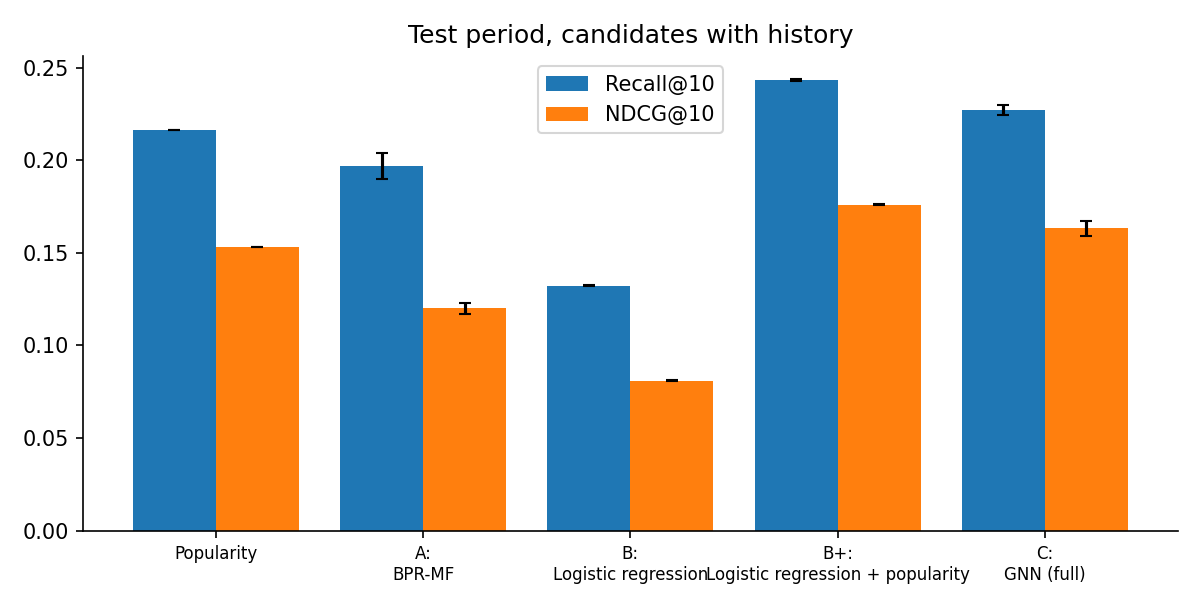

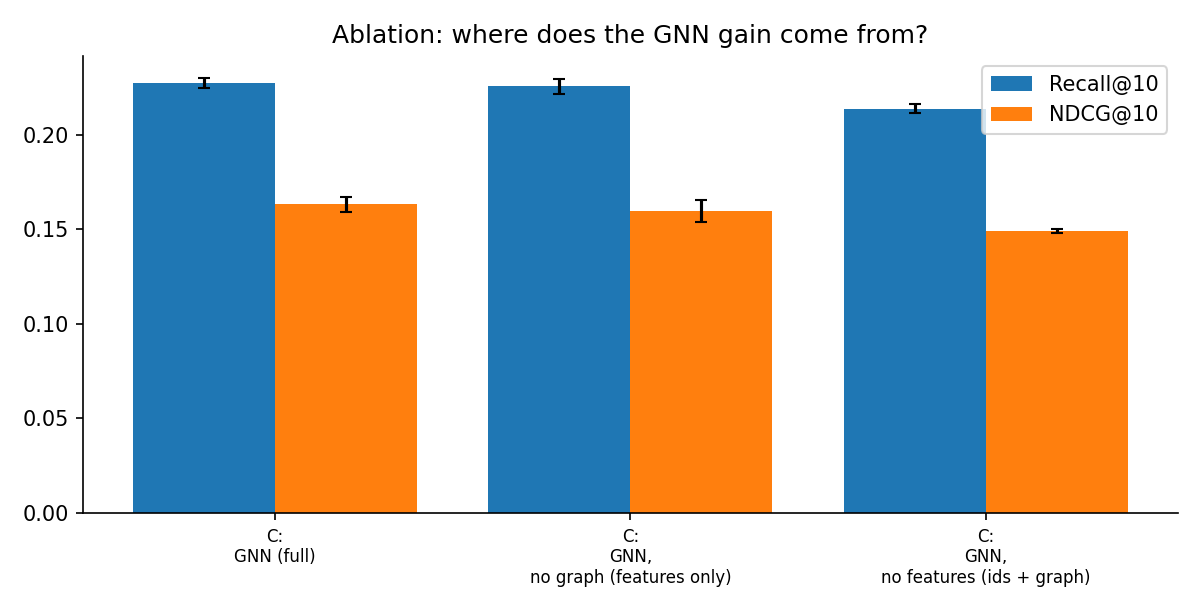

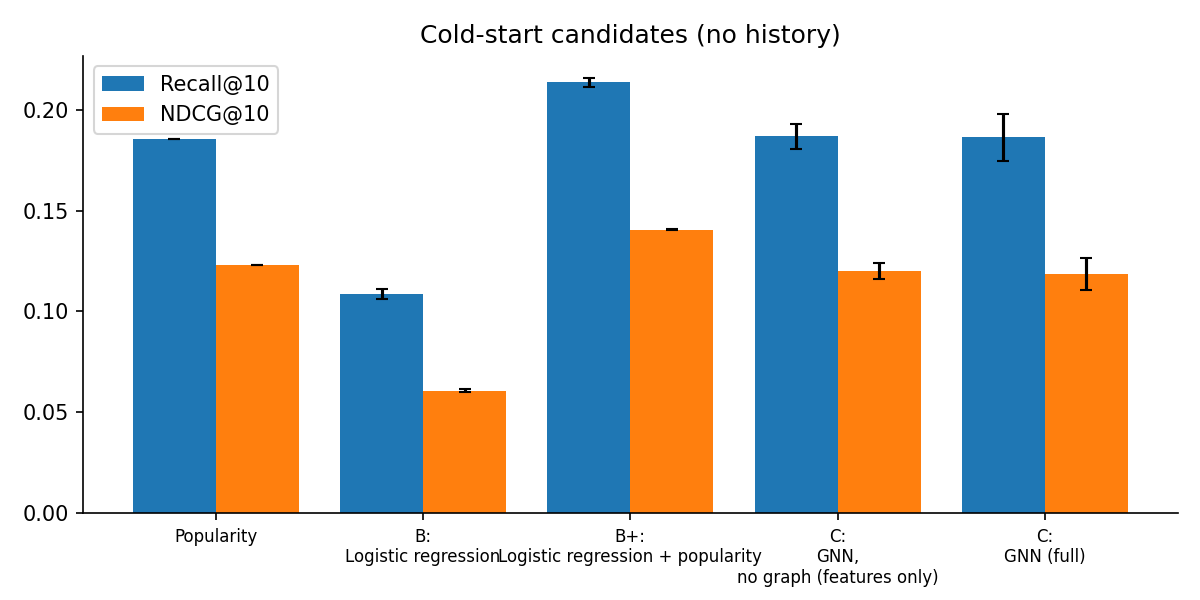

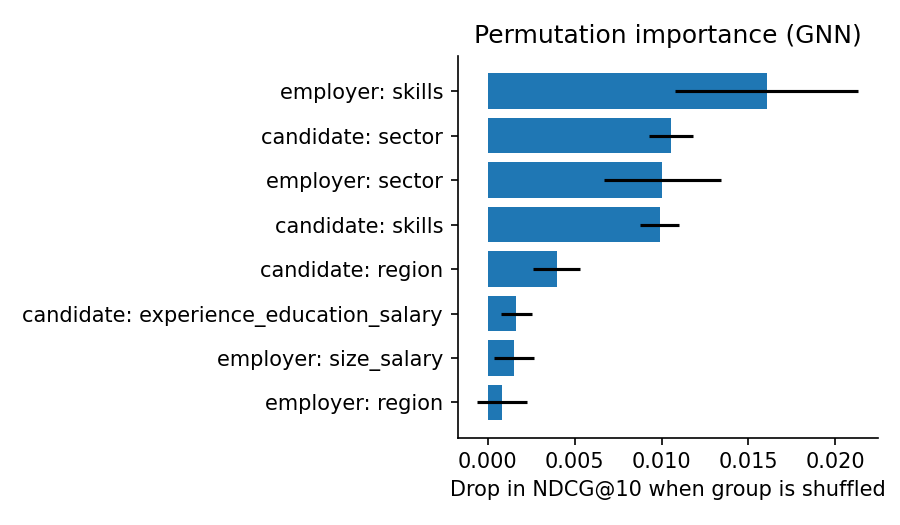

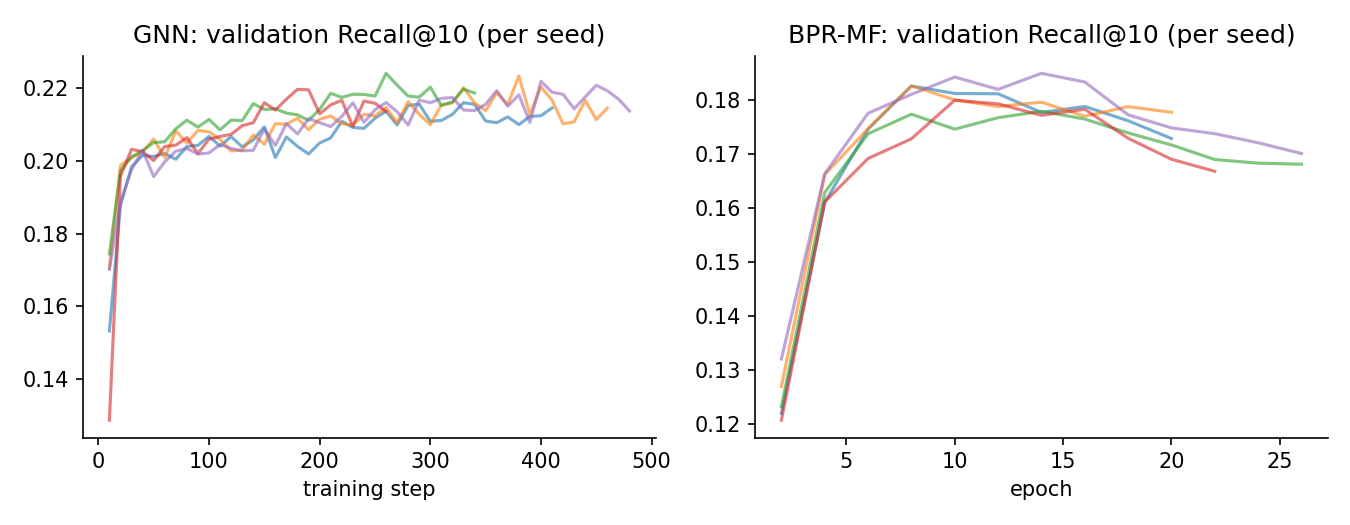

In [ ]:
from IPython.display import Image, display
for f in ("fig_main_comparison.png", "fig_ablation.png", "fig_cold_start.png", "fig_importance.png", "fig_training_curves.png"):
    display(Image(f"{os.environ['MSP_OUT']}/{f}"))